# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u
COSMO = FlatLambdaCDM(H0=70, Om0=0.3)


NETID = 'benh7'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

Hierarchical Model:

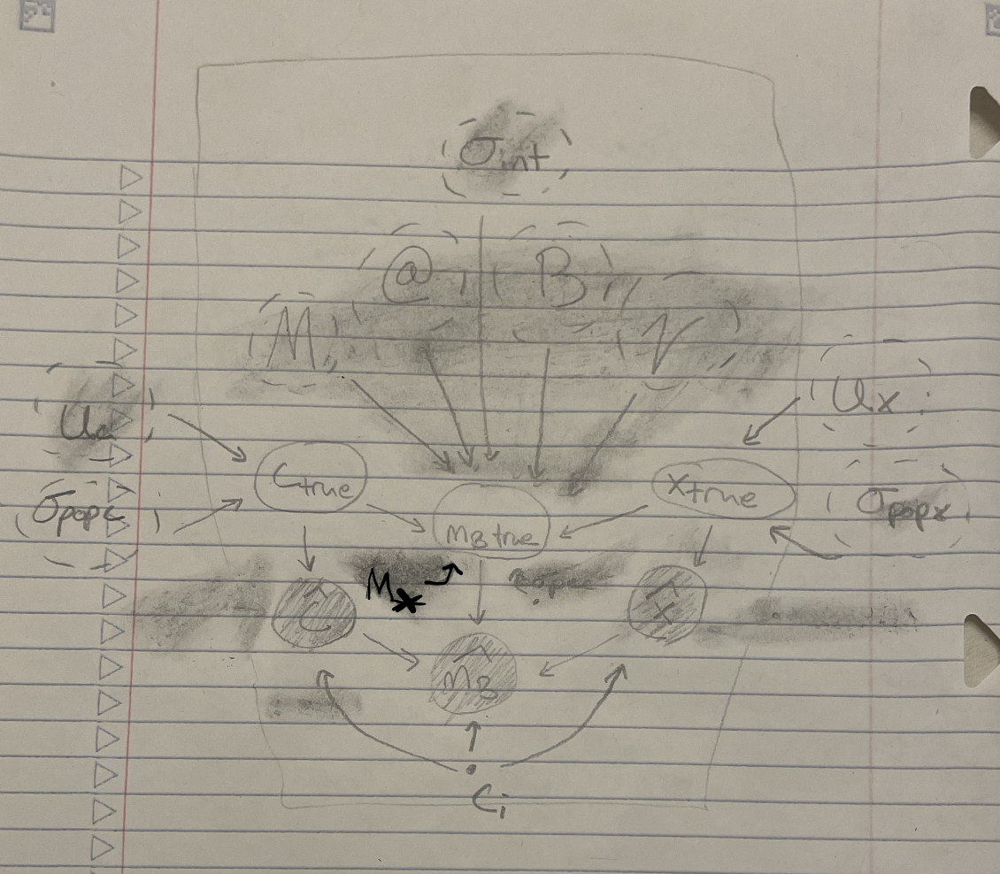

Midterm Model:

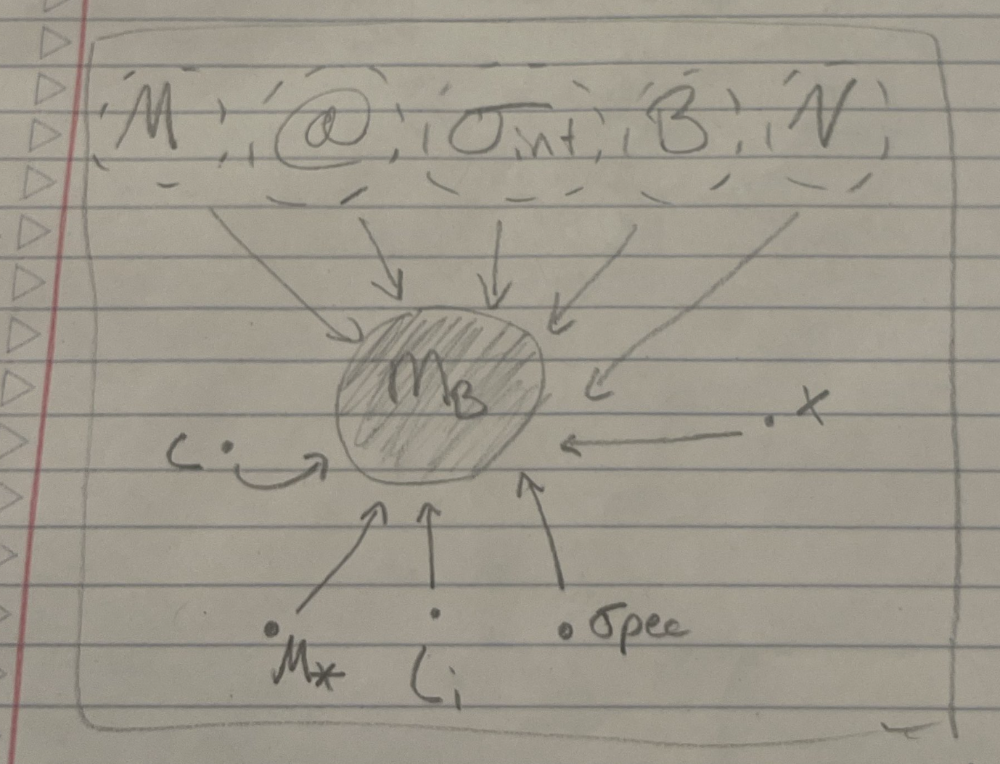

The midterm model made a number of assumptions. It assumed that the mB was what was directly measured. However, this is not the case. mB is made up of fitted parameters as well as the true color and true x location. This results in a true mB (which is white as its never seen). These values are then measured with the noise in them to yield measurements of distance, color, and mB resulting in a new term (mBhat) that is directly measured. The initial model completely missed the arrows connecting the population scatter and means of both color and distance. 

In [3]:
NETID = 'benh7'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

df = load('p2_pantheon_sne')
df

,name,z,mB,mB_err,x1,x1_err,c,c_err,cov_mB_x1,cov_mB_c,cov_x1_c,host_logmass,host_logmass_err
0,000014,0.13614,19.3954,0.044841,0.475770,0.578820,-0.111842,0.033921,0.002586,0.000890,0.001044,9.80415,0.048
1,000137,0.11901,19.6281,0.036931,-0.710055,0.175650,0.081772,0.030635,0.002155,0.000892,0.000521,10.21360,0.035
2,010026,0.03236,16.4521,0.038223,-0.409321,0.082041,-0.031578,0.032595,0.000854,0.001093,0.000205,9.61222,0.010
3,020027,0.11001,19.3621,0.033575,0.296650,0.150750,0.036283,0.029087,-0.000080,0.000835,-0.000914,10.00540,0.107
4,090275,0.13955,19.8340,0.041261,-1.108370,0.173260,-0.037598,0.032102,0.002230,0.001002,0.000990,10.18400,0.008
...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,SN2017cii,0.03289,16.2878,0.060073,0.335440,0.153170,-0.115009,0.036509,-0.002341,0.001817,-0.001248,8.89880,0.002
246,SN2017ciy,0.03834,17.1524,0.058362,1.463100,0.263600,0.012273,0.038448,-0.001076,0.001786,-0.000601,9.70660,0.001
247,SN2017cpu,0.05502,17.1232,0.043441,0.753230,0.342360,-0.060611,0.037778,-0.001084,0.001373,-0.002317,10.52100,0.001
248,SN2017hn,0.02557,16.9198,0.043266,0.624390,0.215660,-0.027287,0.035539,0.000793,0.001269,-0.000558,10.86340,0.001


During the midterm, I used a liklihood function to try and catch the contaminents by finding a gaussianal spread of contaminents within the data. This method caused a lot of issues with my data and created a pileup in estimated fractional values near zero. This also created very unconstrained parameters for the gaussianal spread of contaminents. To account for this improper handling of contaminents, I opted to use the midterm solution's handling of contaminets for my data as this would allow me to have a model that I could directly compare my values against while still being certain I was getting values close to the correct answer. As part of this, I used the solutions method of using the standardized resiudals of redshift to find and cut out the contaminents from the data using this method. The method works by finding a liklihood of values for the Tripp relation and then cutting values that are multiple (5) sigma values for this liklihood of the residual.

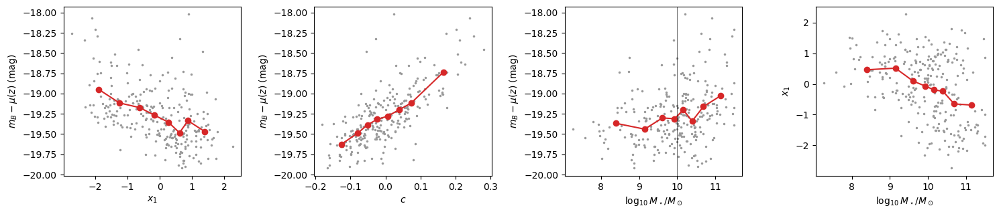

slope of residual vs x1:    -0.159 mag per unit x1
slope of residual vs c:     +2.92 mag per unit c
slope of residual vs mass:  +0.125 mag per dex
corr(x1, mass) = -0.38;  mean x1: low-mass hosts +0.25, high-mass hosts -0.39
largest (fainter) residuals after a plain x1,c regression: [('2006S', np.float64(6.5)), ('2001ah', np.float64(5.6)), ('SN2017hn', np.float64(5.5)), ('15459', np.float64(2.4)), ('SN2017ciy', np.float64(2.2)), ('21062', np.float64(1.9))]


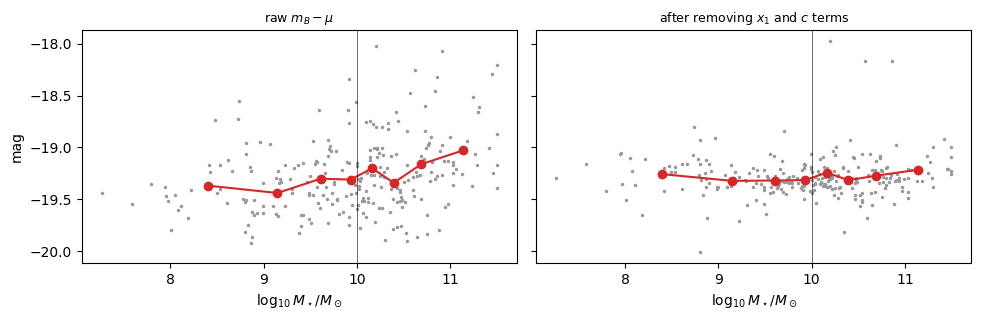

mean residual, low-mass minus high-mass hosts: raw -0.155 mag, after x1,c terms -0.031 mag


In [4]:
# 2a: your work here
sn = df
z, mB, x1, col, lm = (sn[k].to_numpy() for k in ('z', 'mB', 'x1', 'c', 'host_logmass'))
mu = COSMO.distmod(z).value
hres = mB - mu                                   # Hubble residual (absorbs M)

def binned(x, y, n=8):
    edges = np.quantile(x, np.linspace(0, 1, n + 1)); idx = np.clip(np.digitize(x, edges) - 1, 0, n - 1)
    return np.array([x[idx == i].mean() for i in range(n)]), np.array([y[idx == i].mean() for i in range(n)])

fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
for a_, (x, lab) in zip(ax[:3], [(x1, '$x_1$'), (col, '$c$'), (lm, '$\\log_{10} M_\\star/M_\\odot$')]):
    a_.plot(x, hres, '.', ms=3, color='0.6'); a_.plot(*binned(x, hres), 'o-', color='C3'); a_.set_xlabel(lab); a_.set_ylabel('$m_B - \\mu(z)$ (mag)')
ax[3].plot(lm, x1, '.', ms=3, color='0.6'); ax[3].plot(*binned(lm, x1), 'o-', color='C3'); ax[3].set_xlabel('$\\log_{10} M_\\star/M_\\odot$'); ax[3].set_ylabel('$x_1$')
for a_ in ax[:3]: a_.axvline(10, color='k', lw=0.4) if a_ is ax[2] else None
plt.tight_layout(); plt.show()
print(f"slope of residual vs x1:    {np.polyfit(x1, hres, 1)[0]:+.3f} mag per unit x1")
print(f"slope of residual vs c:     {np.polyfit(col, hres, 1)[0]:+.2f} mag per unit c")
print(f"slope of residual vs mass:  {np.polyfit(lm, hres, 1)[0]:+.3f} mag per dex")
print(f"corr(x1, mass) = {np.corrcoef(x1, lm)[0, 1]:+.2f};  mean x1: low-mass hosts {x1[lm < 10].mean():+.2f}, high-mass hosts {x1[lm > 10].mean():+.2f}")

# contaminants: regress out x1 and c only, look at the biggest positive (fainter) residuals
Aq = np.column_stack([np.ones_like(x1), x1, col]); coef, *_ = np.linalg.lstsq(Aq, hres, rcond=None)
rr = hres - Aq @ coef
print("largest (fainter) residuals after a plain x1,c regression:", [(sn['name'][i], round(rr[i] / rr.std(), 1)) for i in np.argsort(rr)[::-1][:6]])
# the same residual against host mass, raw and after removing the x1 and c terms (plain regression)
std_res = hres - (Aq[:, 1:] @ coef[1:])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for a_, y_, lab in zip(ax, (hres, std_res), ('raw $m_B - \\mu$', 'after removing $x_1$ and $c$ terms')):
    a_.plot(lm, y_, '.', ms=3, color='0.6'); a_.plot(*binned(lm, y_), 'o-', color='C3'); a_.axvline(10, color='k', lw=0.4)
    a_.set_xlabel('$\\log_{10} M_\\star/M_\\odot$'); a_.set_title(lab, fontsize=9)
ax[0].set_ylabel('mag'); plt.tight_layout(); plt.show()
print(f"mean residual, low-mass minus high-mass hosts: raw {hres[lm < 10].mean() - hres[lm > 10].mean():+.3f} mag, after x1,c terms {std_res[lm < 10].mean() - std_res[lm > 10].mean():+.3f} mag")

pass 0: N used = 250, sigma_int = 0.169; new cuts (s > 5): [('2001ah', np.float64(5.3)), ('2006S', np.float64(7.1)), ('SN2017hn', np.float64(5.6))]
pass 1: N used = 247, sigma_int = 0.113; new cuts (s > 5): []
removed 3 SNe: ['2001ah', '2006S', 'SN2017hn'];  largest remaining |s| = 3.7


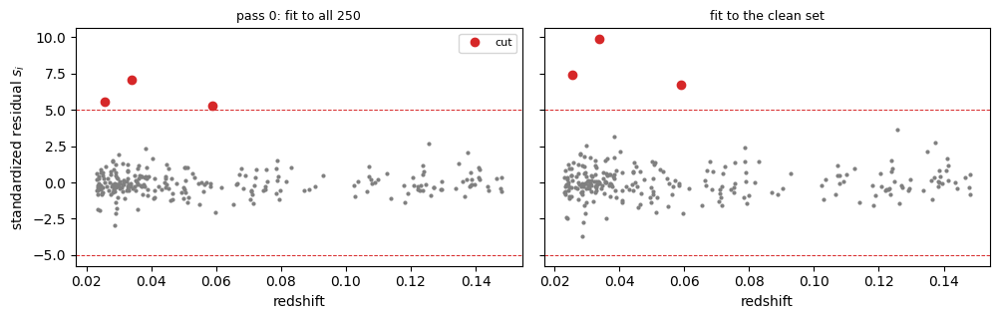

In [5]:
dat = {k: sn[k].to_numpy() for k in sn.columns if k != 'name'}
dat['mu'] = mu
dat['var_pec'] = (5 / np.log(10) * 250 / (2.998e5 * dat['z']))**2
dat['step'] = (dat['host_logmass'] > 10).astype(float)
names = ['M', 'alpha', 'beta', 'gamma', 'ln_sigint']
LO = np.array([-21., 0., 0., -0.2, np.log(0.01)]); HI = np.array([-17., 0.5, 6., 0.2, 0.])   # prior ranges

def subset(sel): return {k: v[sel] for k, v in dat.items()}

def var_i(theta, D):
    M, a, b, g, ls = theta
    # v^T C v with v = (1, alpha, -beta), term by term
    vCv = D['mB_err']**2 + a**2 * D['x1_err']**2 + b**2 * D['c_err']**2 + 2 * a * D['cov_mB_x1'] - 2 * b * D['cov_mB_c'] - 2 * a * b * D['cov_x1_c']
    return vCv + D['var_pec'] + np.exp(2 * ls)

def lnlike(theta, D):
    M, a, b, g, ls = theta
    r = D['mB'] - (M + D['mu'] - a * D['x1'] + b * D['c'] + g * D['step'])
    v = var_i(theta, D)
    return -0.5 * np.sum(r**2 / v + np.log(v) + np.log(2 * np.pi))

def lnpost(theta, D):
    theta = np.asarray(theta)
    return -np.inf if np.any(theta <= LO) or np.any(theta >= HI) else lnlike(theta, D)

def std_resid(theta, D):
    M, a, b, g, ls = theta
    r = D['mB'] - (M + D['mu'] - a * D['x1'] + b * D['c'] + g * D['step'])
    return r / np.sqrt(var_i(theta, D))

def hessian(f, p, h=1e-4):
    n = len(p); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei = np.zeros(n); ej = np.zeros(n); ei[i] = h; ej[j] = h
            H[i, j] = (f(p + ei + ej) - f(p + ei - ej) - f(p - ei + ej) + f(p - ei - ej)) / (4 * h * h)
    return H

def fit(D, start=(-19.3, 0.14, 2.9, -0.04, np.log(0.11))):
    return minimize(lambda p: -lnpost(p, D), start, method='Nelder-Mead', options=dict(maxiter=40000, xatol=1e-9, fatol=1e-9))

# contaminants: iterate fit -> standardized residuals s_i -> cut one-sided (fainter) at 5 sigma, until nothing new is cut
cut = np.zeros(len(sn), bool)
for it in range(5):
    r = fit(subset(~cut)); sr = std_resid(r.x, dat)           # standardized residual s_i of every SN under the fit to the current clean set
    if it == 0: sr0 = sr.copy()
    new = (sr > 5) & ~cut
    print(f"pass {it}: N used = {(~cut).sum()}, sigma_int = {np.exp(r.x[4]):.3f}; new cuts (s > 5): {[(sn['name'][i], round(sr[i], 1)) for i in np.where(new)[0]]}")
    if not new.any(): break
    cut |= new
good = ~cut
print(f"removed {cut.sum()} SNe: {list(sn['name'][cut])};  largest remaining |s| = {np.abs(sr[good]).max():.1f}")
Dg = subset(good)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for a_, s_, lab in zip(ax, (sr0, std_resid(fit(Dg).x, dat)), ('pass 0: fit to all 250', 'fit to the clean set')):
    a_.plot(dat['z'], s_, '.', ms=4, color='0.5'); a_.plot(dat['z'][cut], s_[cut], 'o', color='C3', ms=6, label='cut')
    a_.axhline(5, color='C3', lw=0.7, ls='--'); a_.axhline(-5, color='C3', lw=0.7, ls='--'); a_.set_xlabel('redshift'); a_.set_title(lab, fontsize=9)
ax[0].set_ylabel('standardized residual $s_i$'); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [6]:
sr_clean = std_resid(fit(Dg).x, dat)
for thr in (None, 3.0, 4.0, 5.0):
    sel = np.ones(len(sn), bool) if thr is None else (sr_clean < thr)
    rr_ = fit(subset(sel))
    print(f"cut at s > {thr}:  N = {sel.sum()},  gamma = {rr_.x[3]:+.3f},  sigma_int = {np.exp(rr_.x[4]):.3f},  alpha = {rr_.x[1]:.3f},  beta = {rr_.x[2]:.2f}")

cut at s > None:  N = 250,  gamma = +0.019,  sigma_int = 0.169,  alpha = 0.125,  beta = 2.76
cut at s > 3.0:  N = 245,  gamma = -0.011,  sigma_int = 0.105,  alpha = 0.142,  beta = 2.77
cut at s > 4.0:  N = 247,  gamma = -0.018,  sigma_int = 0.113,  alpha = 0.139,  beta = 2.81
cut at s > 5.0:  N = 247,  gamma = -0.018,  sigma_int = 0.113,  alpha = 0.139,  beta = 2.81


In [7]:
df_clean = pd.DataFrame(Dg)
df_clean

,z,mB,mB_err,x1,x1_err,c,c_err,cov_mB_x1,cov_mB_c,cov_x1_c,host_logmass,host_logmass_err,mu,var_pec,step
0,0.13614,19.3954,0.044841,0.475770,0.578820,-0.111842,0.033921,0.002586,0.000890,0.001044,9.80415,0.048,39.036444,0.000177,0.0
1,0.11901,19.6281,0.036931,-0.710055,0.175650,0.081772,0.030635,0.002155,0.000892,0.000521,10.21360,0.035,38.720436,0.000232,1.0
2,0.03236,16.4521,0.038223,-0.409321,0.082041,-0.031578,0.032595,0.000854,0.001093,0.000205,9.61222,0.010,35.761836,0.003131,0.0
3,0.11001,19.3621,0.033575,0.296650,0.150750,0.036283,0.029087,-0.000080,0.000835,-0.000914,10.00540,0.107,38.536839,0.000271,1.0
4,0.13955,19.8340,0.041261,-1.108370,0.173260,-0.037598,0.032102,0.002230,0.001002,0.000990,10.18400,0.008,39.094873,0.000168,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
242,0.06711,17.8074,0.053369,0.793910,0.354030,-0.114194,0.043204,-0.003760,0.001841,-0.003399,9.99601,0.018,37.400111,0.000728,0.0
243,0.03289,16.2878,0.060073,0.335440,0.153170,-0.115009,0.036509,-0.002341,0.001817,-0.001248,8.89880,0.002,35.797963,0.003031,0.0
244,0.03834,17.1524,0.058362,1.463100,0.263600,0.012273,0.038448,-0.001076,0.001786,-0.000601,9.70660,0.001,36.139608,0.002231,0.0
245,0.05502,17.1232,0.043441,0.753230,0.342360,-0.060611,0.037778,-0.001084,0.001373,-0.002317,10.52100,0.001,36.950167,0.001083,1.0


In [8]:
print("median x1 error =", np.median(df_clean['x1_err']))
print("median c error =", np.median(df_clean['c_err']))

median x1 error = 0.15933
median c error = 0.032914


In [9]:
print("std(x1) =", np.std(df_clean['x1']))
print("std(c)  =", np.std(df_clean['c']))

std(x1) = 1.063069025797145
std(c)  = 0.08943491911752256


In [10]:
print("IQR x1 =", np.percentile(df_clean['x1'], 75) - np.percentile(df_clean['x1'], 25))

print("IQR c =", np.percentile(df_clean['c'], 75) - np.percentile(df_clean['c'], 25))

N = len(df_clean)

IQR x1 = 1.672508
IQR c = 0.1218005


Since the x and c errors are smaller than the spread of the x and c values, I decided to opt for a centered model.

In [11]:
c_light = 299792.458
var_pec = (5 / np.log(10)) * (250) / (c_light * df_clean['z'])

Ci = np.zeros((247, 3, 3))

Ci[:,0,0] = df_clean['mB_err']**2 + var_pec**2
Ci[:,1,1] = df_clean['x1_err']**2
Ci[:,2,2] = df_clean['c_err']**2

Ci[:,0,1] = df_clean['cov_mB_x1']
Ci[:,1,0] = df_clean['cov_mB_x1']

Ci[:,0,2] = df_clean['cov_mB_c']
Ci[:,2,0] = df_clean['cov_mB_c']

Ci[:,1,2] = df_clean['cov_x1_c']
Ci[:,2,1] = df_clean['cov_x1_c']

In [12]:
y_obs = np.column_stack([df_clean['mB'], df_clean['x1'], df_clean['c']])

N = len(df_clean)

with pm.Model() as tripp_hier:
    M = pm.Uniform("M", lower = -21, upper = -17)
    alpha = pm.Uniform("alpha", lower=0, upper=0.5)
    beta = pm.Uniform("beta", lower = 0, upper=6)
    gamma = pm.Uniform("gamma", lower = -0.2, upper = 0.2)
    ln_sigint = pm.Uniform("ln_sigint", lower = np.log(0.01), upper = 0)
    sigma_int = pm.Deterministic("sigma_int", pt.exp(ln_sigint))
    mu_x1 = pm.Normal("mu_x1", mu = 0, sigma = 2)
    sig_x1 = pm.HalfNormal("sig_x1", sigma = 2)
    mu_c = pm.Normal("mu_c", mu = 0, sigma = 0.2)
    sig_c = pm.HalfNormal("sig_c", sigma = 0.2)
    x1_true = pm.Normal("x1_true", mu = mu_x1, sigma = sig_x1, shape = N)
    c_true = pm.Normal("c_true", mu = mu_c, sigma = sig_c, shape = N)
    step = df_clean['step'].to_numpy()
    mu_dist = df_clean['mu'].to_numpy()

    mB_true = (M + mu_dist - alpha * x1_true + beta * c_true + gamma * step)
    mu_vec = pt.stack([mB_true, x1_true, c_true], axis = 1)

    Sigma = pt.as_tensor_variable(Ci)
    Sigma = pt.set_subtensor(Sigma[:,0,0], Sigma[:,0,0] + sigma_int**2)

    obs = pm.MvNormal("obs", mu = mu_vec, cov = Sigma, observed = y_obs)

In [13]:
print(y_obs.shape)
print(Ci.shape)

(247, 3)
(247, 3, 3)


In [14]:
np.allclose(
    Ci,
    Ci.transpose(0,2,1)
)

True

In [15]:
with tripp_hier:
    trace = pm.sample(draws = 2000, tune = 2000, chains = 4, target_accept = 0.9, return_inferencedata = True)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigint, mu_x1, sig_x1, mu_c, sig_c, x1_true, c_true]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 58 seconds.


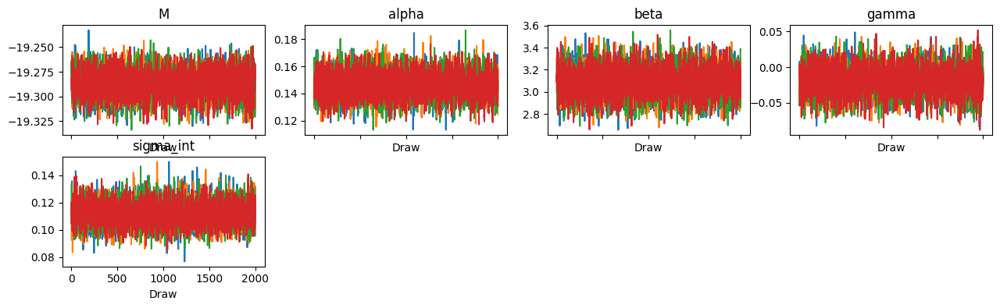

In [16]:
az.plot_trace(trace, var_names=["M","alpha","beta","gamma","sigma_int"])

In [17]:
full_summary = az.summary(trace)
full_summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_x1,-0.117,0.0677,-0.22,-0.0091,11534,6436,1.00,0.00063,0.00045
mu_c,-0.0007,0.00569,-0.0097,0.0083,8673,5961,1.00,6.1e-05,4.3e-05
x1_true[0],0.34,0.449,-0.37,1.1,12580,6588,1.00,0.004,0.0028
x1_true[1],-0.664,0.166,-0.93,-0.4,12353,5726,1.00,0.0015,0.0011
x1_true[2],-0.406,0.082,-0.54,-0.27,15137,5657,1.00,0.00067,0.00048
...,...,...,...,...,...,...,...,...,...
gamma,-0.0191,0.0191,-0.05,0.011,5356,5790,1.00,0.00026,0.00019
ln_sigint,-2.196,0.078,-2.3,-2.1,4895,5828,1.00,0.0011,0.0008
sig_x1,1.0465,0.0493,0.97,1.1,11852,6415,1.00,0.00045,0.00033
sig_c,0.0815,0.00439,0.075,0.089,7423,6267,1.00,5.1e-05,3.8e-05


In [18]:
summary = az.summary(trace, var_names=["M", "alpha", "beta", "gamma", "sigma_int", "mu_x1", "sig_x1", "mu_c", "sig_c"])
summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
M,-19.2874,0.0134,-19,-19,5470,5785,1.00,0.00018,0.00013
alpha,0.1465,0.0094,0.13,0.16,6692,6041,1.00,0.00011,8.2e-05
beta,3.089,0.127,2.9,3.3,5484,6043,1.00,0.0017,0.0012
gamma,-0.0191,0.0191,-0.05,0.011,5356,5790,1.00,0.00026,0.00019
sigma_int,0.1116,0.0086,0.098,0.13,4895,5828,1.00,0.00012,9e-05
mu_x1,-0.117,0.0677,-0.22,-0.0091,11534,6436,1.00,0.00063,0.00045
sig_x1,1.0465,0.0493,0.97,1.1,11852,6415,1.00,0.00045,0.00033
mu_c,-0.0007,0.00569,-0.0097,0.0083,8673,5961,1.00,6.1e-05,4.3e-05
sig_c,0.0815,0.00439,0.075,0.089,7423,6267,1.00,5.1e-05,3.8e-05


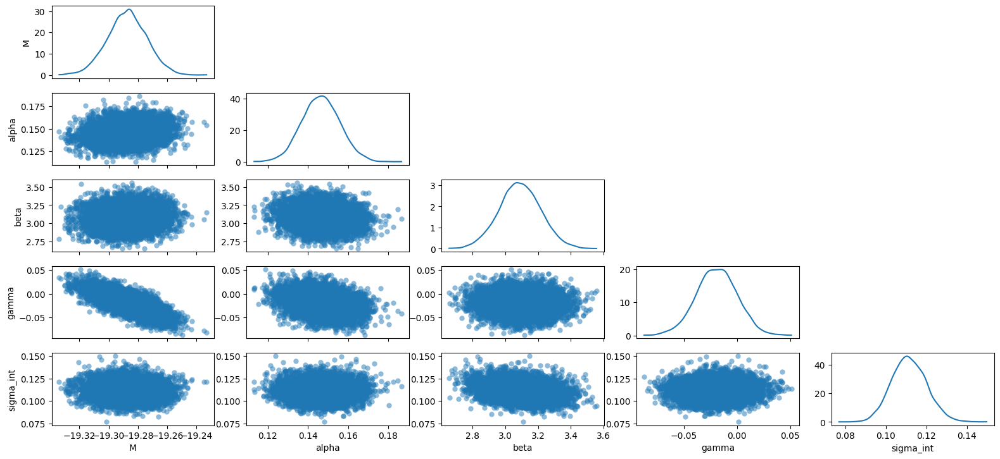

In [19]:
az.plot_pair(trace, var_names = ["M", "alpha", "beta", "gamma", "sigma_int"])

In [20]:
print(f'Largest Rhat is: {summary['r_hat'].max()}')

Largest Rhat is: 1.00


In [21]:
print(f'The parameter with the smallest bulk effective sample size is: {full_summary["ess_bulk"].idxmin()}')
print(f'With an effective sample size of: {full_summary['ess_bulk'][full_summary["ess_bulk"].idxmin()]}')

The parameter with the smallest bulk effective sample size is: ln_sigint
With an effective sample size of: 4895


In [22]:
params = ["M", "alpha", "beta", "gamma", "sigma_int"]

print('Current Statistics:')
for p in params:
    samples = trace.posterior[p].values.flatten()

    lo, med, hi = np.percentile(samples, [16, 50, 84])
    lo_r = med - lo
    hi_r = hi - med

    print(f'{p:10s}= {med:.3f} + {hi_r:.3f} or - {lo_r:.3f}')

print('')
print('Previous Statistics:')
print('M         = -19.2860 +0.0133 or -0.0131')
print('alpha     = 0.1390 +0.0091 or -0.0092')
print('beta      = 2.8168 +0.1064 or -0.1054')
print('gamma     = -0.0189 +0.0188 or -0.0191')
print('sigma_int = 0.1143 +0.0086 or -0.0081')

Current Statistics:
M         = -19.287 + 0.013 or - 0.013
alpha     = 0.146 + 0.009 or - 0.009
beta      = 3.088 + 0.127 or - 0.122
gamma     = -0.019 + 0.019 or - 0.019
sigma_int = 0.111 + 0.009 or - 0.008

Previous Statistics:
M         = -19.2860 +0.0133 or -0.0131
alpha     = 0.1390 +0.0091 or -0.0092
beta      = 2.8168 +0.1064 or -0.1054
gamma     = -0.0189 +0.0188 or -0.0191
sigma_int = 0.1143 +0.0086 or -0.0081


param        truth    mean est   mean sigma   coverage   mean pull +/- se
M            -19.300    -19.303      0.0130       0.70     -0.21 +/- 0.07
alpha          0.140      0.135      0.0086       0.61     -0.57 +/- 0.06
beta           2.900      2.680      0.0945       0.06     -2.33 +/- 0.06
gamma         -0.060     -0.053      0.0183       0.64     +0.40 +/- 0.07
ln_sigint     -2.207     -2.209      0.0701       0.67     +0.03 +/- 0.07

control (regressors exact):  coverage [0.71 0.68 0.64 0.72 0.69]   mean pull [-0.01  0.01  0.05  0.01 -0.33]
c: noise fraction 0.152, error-covariance term +0.063 -> expected coefficient ratio 0.922;  simulated 0.924
x1: noise fraction 0.045, error-covariance term -0.008 -> expected coefficient ratio 0.949;  simulated 0.965


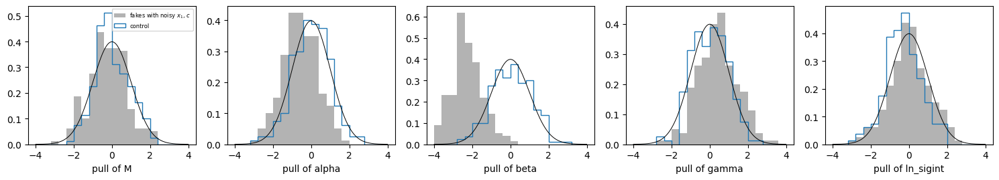

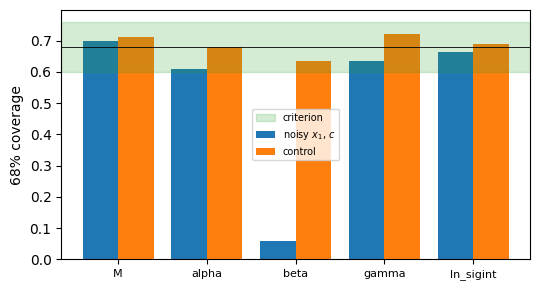

In [23]:
#Initial Model
Cfull = np.zeros((len(sn), 3, 3))
Cfull[:, 0, 0], Cfull[:, 1, 1], Cfull[:, 2, 2] = dat['mB_err']**2, dat['x1_err']**2, dat['c_err']**2
Cfull[:, 0, 1] = Cfull[:, 1, 0] = dat['cov_mB_x1']; Cfull[:, 0, 2] = Cfull[:, 2, 0] = dat['cov_mB_c']; Cfull[:, 1, 2] = Cfull[:, 2, 1] = dat['cov_x1_c']
Lc = np.linalg.cholesky(Cfull)                       # all covariances are positive definite in this file
truth_ = np.array([-19.30, 0.14, 2.9, -0.06, np.log(0.11)])
sim_rng = np.random.default_rng(2026)
est, err = [], []
for isim in range(200):
    e3 = np.einsum('nij,nj->ni', Lc, sim_rng.standard_normal((len(sn), 3)))
    Ds = dict(dat)
    Ds['x1'], Ds['c'] = dat['x1'] + e3[:, 1], dat['c'] + e3[:, 2]
    Ds['mB'] = (truth_[0] + dat['mu'] - truth_[1] * dat['x1'] + truth_[2] * dat['c'] + truth_[3] * dat['step']
                + e3[:, 0] + np.exp(truth_[4]) * sim_rng.standard_normal(len(sn)) + np.sqrt(dat['var_pec']) * sim_rng.standard_normal(len(sn)))
    rs = minimize(lambda p: -lnpost(p, Ds), (-19.2, 0.1, 2.5, 0.0, np.log(0.1)), method='Nelder-Mead', options=dict(maxiter=40000, xatol=1e-8, fatol=1e-8))
    est.append(rs.x); err.append(np.sqrt(np.diag(np.linalg.inv(hessian(lambda p: -lnlike(p, Ds), rs.x)))))
est, err = np.array(est), np.array(err)
cover = np.mean(np.abs(est - truth_) < err, axis=0); pull = (est - truth_) / err
print("param        truth    mean est   mean sigma   coverage   mean pull +/- se")
for i, n in enumerate(names):
    print(f"{n:10s} {truth_[i]:9.3f} {est[:, i].mean():10.3f} {err[:, i].mean():11.4f} {cover[i]:10.2f} {pull[:, i].mean():+9.2f} +/- {pull[:, i].std() / np.sqrt(len(pull)):.2f}")

# why is beta low? control: same fake data but the regressors x1, c are NOT perturbed (their noise enters only through the m_B scatter)
est_c, err_c = [], []
for isim in range(200):
    e3 = np.einsum('nij,nj->ni', Lc, sim_rng.standard_normal((len(sn), 3)))
    Ds = dict(dat)
    Ds['mB'] = (truth_[0] + dat['mu'] - truth_[1] * dat['x1'] + truth_[2] * dat['c'] + truth_[3] * dat['step']
                + e3[:, 0] + truth_[1] * e3[:, 1] - truth_[2] * e3[:, 2]
                + np.exp(truth_[4]) * sim_rng.standard_normal(len(sn)) + np.sqrt(dat['var_pec']) * sim_rng.standard_normal(len(sn)))
    rs = minimize(lambda p: -lnpost(p, Ds), (-19.2, 0.1, 2.5, 0.0, np.log(0.1)), method='Nelder-Mead', options=dict(maxiter=40000, xatol=1e-8, fatol=1e-8))
    est_c.append(rs.x); err_c.append(np.sqrt(np.diag(np.linalg.inv(hessian(lambda p: -lnlike(p, Ds), rs.x)))))
est_c, err_c = np.array(est_c), np.array(err_c)
cover_c = np.mean(np.abs(est_c - truth_) < err_c, axis=0); pull_c = (est_c - truth_) / err_c
print("\ncontrol (regressors exact):  coverage", np.round(cover_c, 2), "  mean pull", np.round(pull_c.mean(axis=0), 2))

# size of the effect: regression dilution. Expected slope ratio = (1 + error-covariance term) / (1 + noise fraction of the regressor's variance), 1/variance weights
w_ = 1 / var_i(truth_, dat)
for nm_, x_, ex_, cmb_, coef_, i_ in (('c', dat['c'], dat['c_err'], dat['cov_mB_c'], truth_[2], 2), ('x1', dat['x1'], dat['x1_err'], dat['cov_mB_x1'], -truth_[1], 1)):
    S_ = np.sum(w_ * (x_ - np.average(x_, weights=w_))**2)
    noise, covterm = np.sum(w_ * ex_**2) / S_, np.sum(w_ * cmb_) / (coef_ * S_)
    print(f"{nm_}: noise fraction {noise:.3f}, error-covariance term {covterm:+.3f} -> expected coefficient ratio {(1 + covterm) / (1 + noise):.3f};  simulated {est[:, i_].mean() / truth_[i_]:.3f}")
fig, ax = plt.subplots(1, 5, figsize=(15, 2.8))
xg = np.linspace(-4, 4, 200)
for i_, n_ in enumerate(names):
    ax[i_].hist(pull[:, i_], 20, range=(-4, 4), density=True, color='0.7', label='fakes with noisy $x_1$, $c$'); ax[i_].hist(pull_c[:, i_], 20, range=(-4, 4), density=True, histtype='step', color='C0', label='control')
    ax[i_].plot(xg, stats.norm.pdf(xg), 'k', lw=0.7); ax[i_].set_xlabel(f'pull of {n_}')
ax[0].legend(fontsize=6); plt.tight_layout(); plt.show()
plt.figure(figsize=(5.5, 3)); xb = np.arange(5)
plt.bar(xb - 0.2, cover, 0.4, label='noisy $x_1$, $c$'); plt.bar(xb + 0.2, cover_c, 0.4, label='control')
plt.axhspan(0.60, 0.76, color='C2', alpha=0.2, label='criterion'); plt.axhline(0.68, color='k', lw=0.6)
plt.xticks(xb, names, fontsize=8); plt.ylabel('68% coverage'); plt.legend(fontsize=7); plt.tight_layout(); plt.show()

In [24]:
#Hierarchical Model
def build_latent_model(DataSet):

    N = len(DataSet['mB'])
    
    Ci_sim = np.zeros((N,3,3))

    Ci_sim[:,0,0] = DataSet['mB_err']**2
    Ci_sim[:,1,1] = DataSet['x1_err']**2
    Ci_sim[:,2,2] = DataSet['c_err']**2
    
    Ci_sim[:,0,1] = Ci_sim[:,1,0] = DataSet['cov_mB_x1']
    Ci_sim[:,0,2] = Ci_sim[:,2,0] = DataSet['cov_mB_c']
    Ci_sim[:,1,2] = Ci_sim[:,2,1] = DataSet['cov_x1_c']

    y_obs = np.column_stack([DataSet['mB'], DataSet['x1'], DataSet['c']])
    
    with pm.Model() as model:
        M = pm.Uniform("M", lower = -21, upper = -17)
        alpha = pm.Uniform("alpha", lower=0, upper=0.5)
        beta = pm.Uniform("beta", lower = 0, upper=6)
        gamma = pm.Uniform("gamma", lower = -0.2, upper = 0.2)
        ln_sigint = pm.Uniform("ln_sigint", lower = np.log(0.01), upper = 0)
        sigma_int = pm.Deterministic("sigma_int", pt.exp(ln_sigint))
        mu_x1 = pm.Normal("mu_x1", mu = 0, sigma = 2)
        sig_x1 = pm.HalfNormal("sig_x1", sigma = 2)
        mu_c = pm.Normal("mu_c", mu = 0, sigma = 0.2)
        sig_c = pm.HalfNormal("sig_c", sigma = 0.2)
        x1_true = pm.Normal("x1_true", mu = mu_x1, sigma = sig_x1, shape = N)
        c_true = pm.Normal("c_true", mu = mu_c, sigma = sig_c, shape = N)
        
        step = np.asarray(DataSet['step'])
        mu_dist = np.asarray(DataSet['mu'])
        
        mB_true = (M + mu_dist - alpha * x1_true + beta * c_true + gamma * step)
        mu_vec = pt.stack([mB_true, x1_true, c_true], axis = 1)
        
        Sigma = pt.as_tensor_variable(Ci_sim)
        Sigma = pt.set_subtensor(Sigma[:,0,0], Sigma[:,0,0] + sigma_int**2)
        
        obs = pm.MvNormal("obs", mu = mu_vec, cov = Sigma, observed = y_obs)

    return model

Cfull = np.zeros((N,3,3))

Cfull[:,0,0] = df_clean['mB_err']**2
Cfull[:,1,1] = df_clean['x1_err']**2
Cfull[:,2,2] = df_clean['c_err']**2

Cfull[:,0,1] = Cfull[:,1,0] = df_clean['cov_mB_x1']
Cfull[:,0,2] = Cfull[:,2,0] = df_clean['cov_mB_c']
Cfull[:,1,2] = Cfull[:,2,1] = df_clean['cov_x1_c']


Lc = np.linalg.cholesky(Cfull)                       # all covariances are positive definite in this file
truth_ = np.array([-19.30, 0.14, 2.9, -0.06, np.log(0.11)])
sim_rng = np.random.default_rng(2026)
beta_midterm = []
beta_hier = []

for isim in range(50):
    e3 = np.einsum('nij,nj->ni', Lc, sim_rng.standard_normal((len(df_clean), 3)))
    Ds = dict(df_clean)
    Ds['x1'], Ds['c'] = df_clean['x1'] + e3[:, 1], df_clean['c'] + e3[:, 2]
    Ds['mB'] = (truth_[0] + df_clean['mu'] - truth_[1] * df_clean['x1'] + truth_[2] * df_clean['c'] + truth_[3] * df_clean['step']
                + e3[:, 0] + np.exp(truth_[4]) * sim_rng.standard_normal(len(df_clean)) + np.sqrt(df_clean['var_pec']) * sim_rng.standard_normal(len(df_clean)))
    rs = minimize(lambda p: -lnpost(p, Ds), (-19.2, 0.1, 2.5, 0.0, np.log(0.1)), method='Nelder-Mead', options=dict(maxiter=40000, xatol=1e-8, fatol=1e-8))
    beta_midterm.append(rs.x[2])

    m = build_latent_model(Ds)

    with m:
        sim_trace = pm.sample(draws = 1000, tune = 1000, chains = 4, progressbar = False)

    beta_hier.append(sim_trace.posterior["beta"])





    

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigint, mu_x1, sig_x1, mu_c, sig_c, x1_true, c_true]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 31 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigint, mu_x1, sig_x1, mu_c, sig_c, x1_true, c_true]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 30 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigint, mu_x1, sig_x1, mu_c, sig_c, x1_true, c_true]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 30 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigint, mu_x1, sig_x1, mu_c, sig_c, x1_true, 

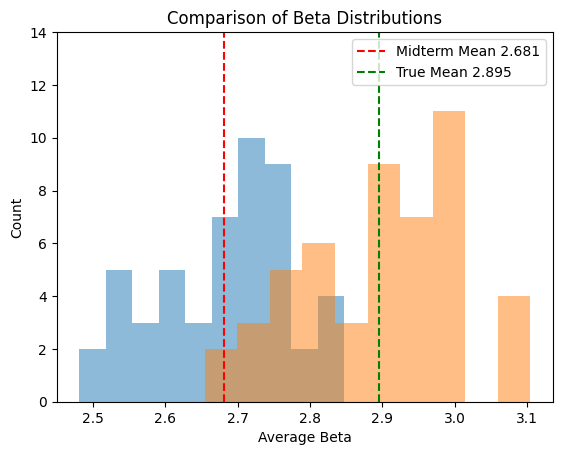

In [25]:
plt.hist(beta_midterm, alpha = .5)

beta_means = [b.mean().item() for b in beta_hier]

plt.hist(beta_means, alpha = .5)

midterm_mean = np.mean(np.array(beta_midterm))
hier_mean = np.mean(np.array(beta_means))

plt.vlines(midterm_mean, ymin = 0, ymax = 15, linestyle = '--', color = 'red', label = f'Midterm Mean {midterm_mean:.3f}')
plt.vlines(hier_mean, ymin = 0, ymax = 15, linestyle = '--', color = 'green', label = f'True Mean {hier_mean:.3f}')

plt.title('Comparison of Beta Distributions')
plt.xlabel('Average Beta')
plt.ylabel('Count')

plt.ylim([0, 14])
plt.legend()

In [26]:
se_midterm = np.std(beta_midterm, ddof = 1) / np.sqrt(50)
se_hier = np.std(beta_means, ddof = 1) / np.sqrt(50)

print(f'Standard Error Midterm: {se_midterm:.3f}')
print(f'Standard Error Hierarchy Model: {se_hier:.3f}')

Standard Error Midterm: 0.013
Standard Error Hierarchy Model: 0.015


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

Hierarchical Model:

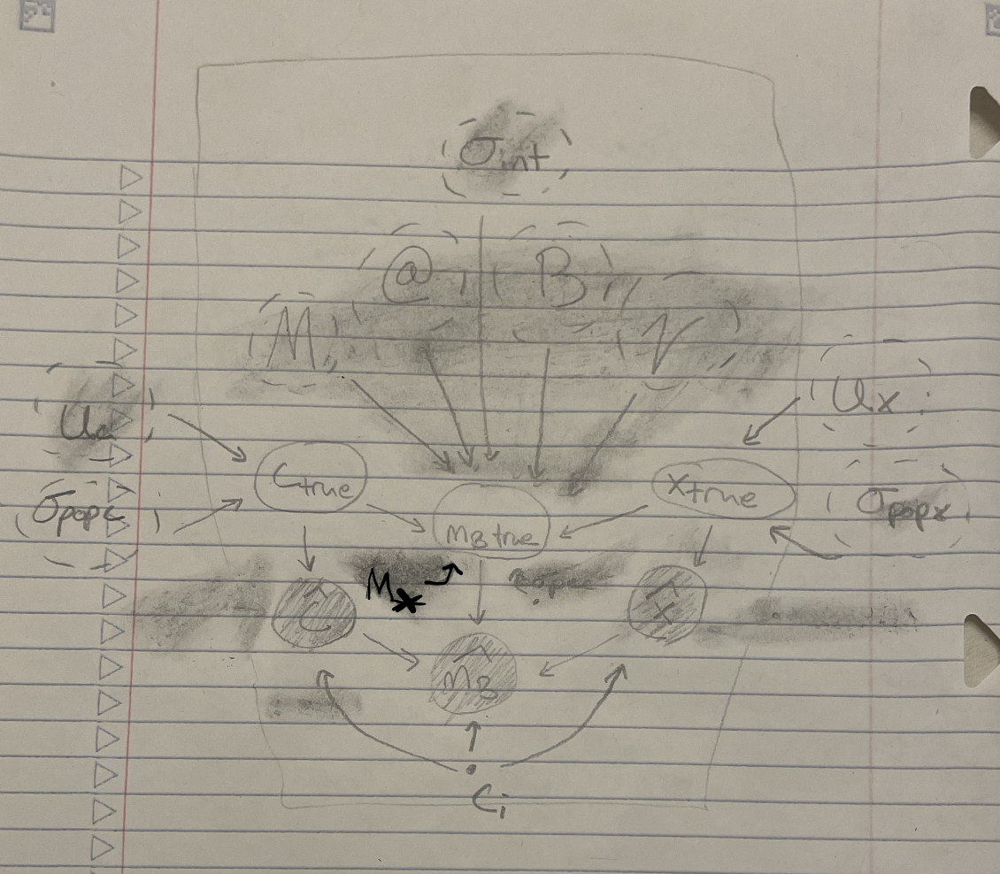

Midterm Model:

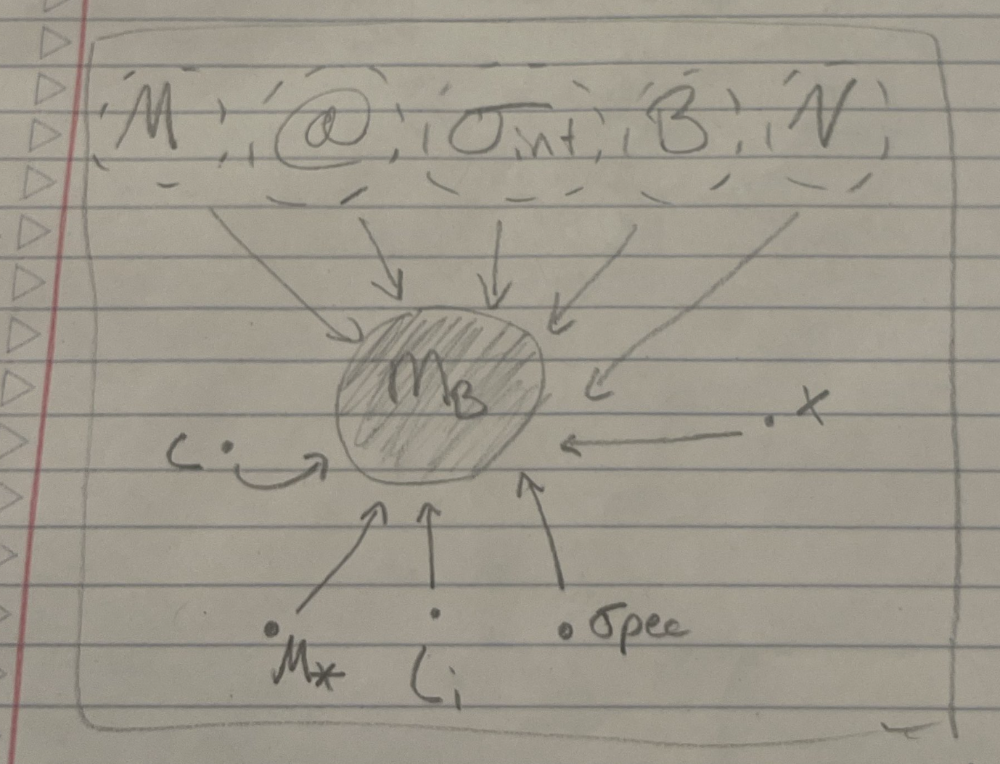

Table:

In [66]:
params = ["M", "alpha", "beta", "gamma", "sigma_int"]

print('Current Statistics:')
for p in params:
    samples = trace.posterior[p].values.flatten()

    lo, med, hi = np.percentile(samples, [16, 50, 84])
    lo_r = med - lo
    hi_r = hi - med

    print(f'{p:10s}= {med:.3f} + {hi_r:.3f} or - {lo_r:.3f}')

print('')
print('Previous Statistics:')
print('M         = -19.2860 +0.0133 or -0.0131')
print('alpha     = 0.1390 +0.0091 or -0.0092')
print('beta      = 2.8168 +0.1064 or -0.1054')
print('gamma     = -0.0189 +0.0188 or -0.0191')
print('sigma_int = 0.1143 +0.0086 or -0.0081')

Current Statistics:
M         = -19.287 + 0.013 or - 0.013
alpha     = 0.146 + 0.009 or - 0.009
beta      = 3.088 + 0.127 or - 0.122
gamma     = -0.019 + 0.019 or - 0.019
sigma_int = 0.111 + 0.009 or - 0.008

Previous Statistics:
M         = -19.2860 +0.0133 or -0.0131
alpha     = 0.1390 +0.0091 or -0.0092
beta      = 2.8168 +0.1064 or -0.1054
gamma     = -0.0189 +0.0188 or -0.0191
sigma_int = 0.1143 +0.0086 or -0.0081


Simulation Results:

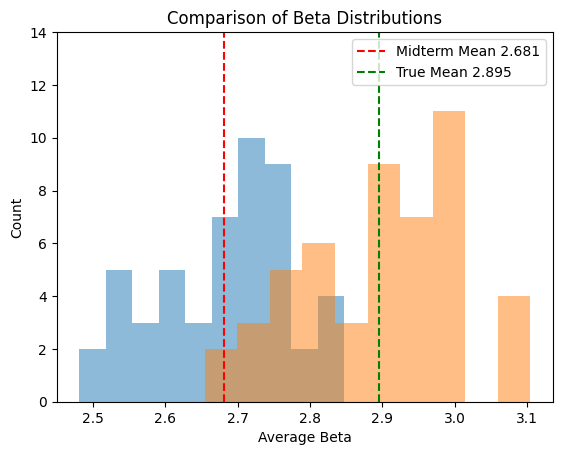

In [67]:
plt.hist(beta_midterm, alpha = .5)

beta_means = [b.mean().item() for b in beta_hier]

plt.hist(beta_means, alpha = .5)

midterm_mean = np.mean(np.array(beta_midterm))
hier_mean = np.mean(np.array(beta_means))

plt.vlines(midterm_mean, ymin = 0, ymax = 15, linestyle = '--', color = 'red', label = f'Midterm Mean {midterm_mean:.3f}')
plt.vlines(hier_mean, ymin = 0, ymax = 15, linestyle = '--', color = 'green', label = f'True Mean {hier_mean:.3f}')

plt.title('Comparison of Beta Distributions')
plt.xlabel('Average Beta')
plt.ylabel('Count')

plt.ylim([0, 14])
plt.legend()

Standard Error Midterm: 0.013

Standard Error Hierarchy Model: 0.015

The noise within x and c and their population scatter creates a spread in their values. When these values are treated as fixed values, this scatter enters the data. If the data is not handled, the trend appears less strong. If this scatter is accounted for, then the spread is taken into account and more of the spread can be explained. This makes the effect of B appear stronger and more defined. This bias has a stronger effect on B as c's error makes up a larger percentage of its scatter. As more of the scatter is accounted for by noise, more of the spread is truthfully included in the data, resulting in an answer closer to the proper value.*

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [27]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

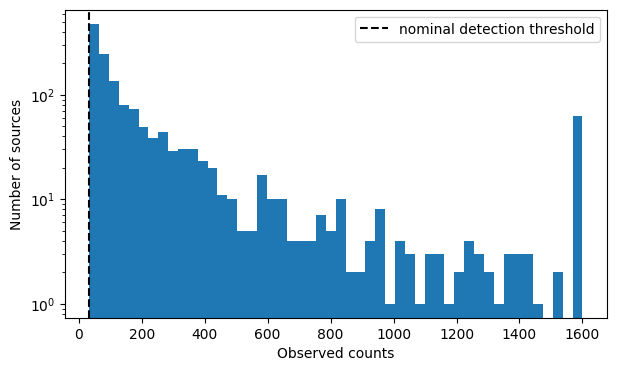

In [28]:
plt.figure(figsize=(7,4))

plt.hist(n, bins = 50)

plt.axvline(32, color = 'black', linestyle = '--', label = 'nominal detection threshold')

plt.yscale('log')

plt.xlabel("Observed counts")
plt.ylabel("Number of sources")
plt.legend()

In [29]:
pile_up = (n == 1600)
print(f'There are {len(n[pile_up])} points at 1600')
print(f'This is {len(n[pile_up]) / len(n) * 100}% of the data.')

There are 57 points at 1600
This is 3.8% of the data.


I found that there is a pileup of observed values at 1600. Rather than counting continuously, after 1600 counts the value becomes saturated and doesn't increase anymore. There were 57 points piled up here (about 3.8% of the data). To account for this I decided to implament a right censoring algortithm to account for this tail. I chose this option as it allows me to continue using my data without throwing anything I detected out. This also allows for the fact that these points don't actually look like this to be reflected as well. 

In [30]:
from scipy.special import gammainc
from scipy.stats import poisson

def pdet_gamma(F):
    lam = eps*F + nu
    return gammainc(33, lam)
        

def pdet_sf(F):
    lam = eps*F + nu
    return poisson.sf(32, lam)


test_fluxes = [0.02, 0.05, 0.10, 0.20, 0.50]

for F in test_fluxes:
    print(f"F={F:.2f}", f"gamma={pdet_gamma(F):.6f}", f"sf={pdet_sf(F):.6f}")

F=0.02 gamma=0.000009 sf=0.000009
F=0.05 gamma=0.007566 sf=0.007566
F=0.10 gamma=0.453171 sf=0.453171
F=0.20 gamma=0.999350 sf=0.999350
F=0.50 gamma=1.000000 sf=1.000000


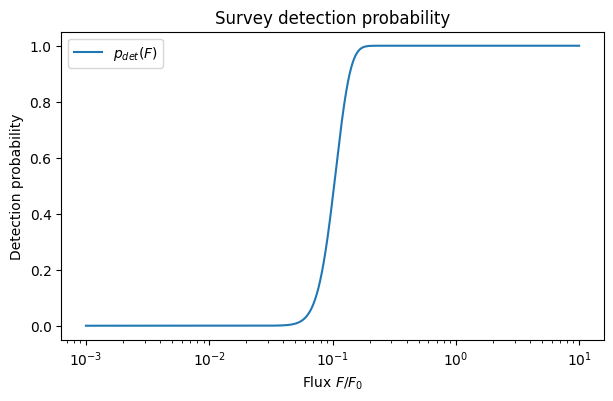

In [31]:
F_grid = np.logspace(-3, 1, 1000)

plt.figure(figsize=(7,4))
plt.plot(F_grid, pdet_gamma(F_grid), label=r'$p_{det}(F)$')

plt.xscale('log')

plt.xlabel('Flux $F/F_0$')
plt.ylabel('Detection probability')

plt.title('Survey detection probability')

plt.legend()

In [32]:
from scipy.optimize import brentq

F_half = brentq(lambda F: pdet_gamma(F) - 0.5, 1e-4, 1.0)

print("50% detection flux =", F_half)

50% detection flux = 0.10294900731085659


Half detection is at ~.103

Graph:

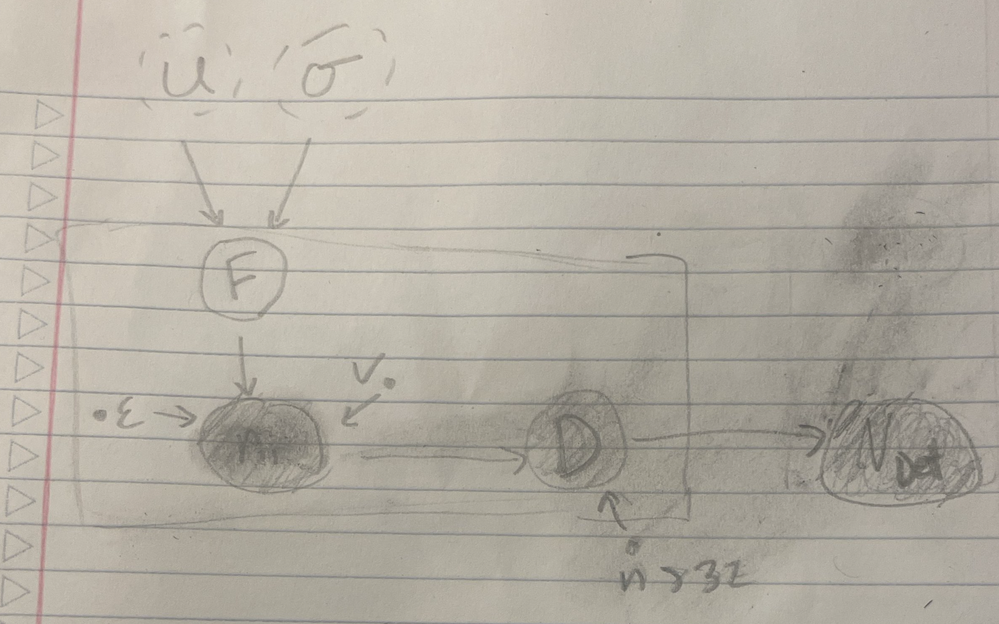

In [68]:
from scipy.stats import norm

lnF_grid = np.linspace(-14, 8, 4000)
F_grid = np.exp(lnF_grid)

def p_n_given_mu_sigma(n_obs, mu, sigma):

    prior = norm.pdf(lnF_grid, loc = mu, scale = sigma)

    lam = eps*F_grid + nu

    if n_obs < 1600:

        like = poisson.pmf(n_obs, lam)

    else:

        like = poisson.sf(1599, lam)

    integrand = (like * prior)

    return np.trapezoid(integrand, lnF_grid)

def lnlike_naive1(theta):

    mu, sigma = theta

    if sigma <= 0:
        return -np.inf

    probs = np.array([p_n_given_mu_sigma(ni, mu, sigma) for ni in n])

    return np.sum(np.log(probs))

In [69]:
res_naive = minimize(lambda p: -lnlike_naive(p), x0 = (-2.0, 1.0), method='Nelder-Mead')
print(res_naive.x)

[-0.64490972  1.20103322]


In [70]:
mu_naive, sigma_naive = res_naive.x

Text(0.5, 1.0, 'Liklihood about Sigma')

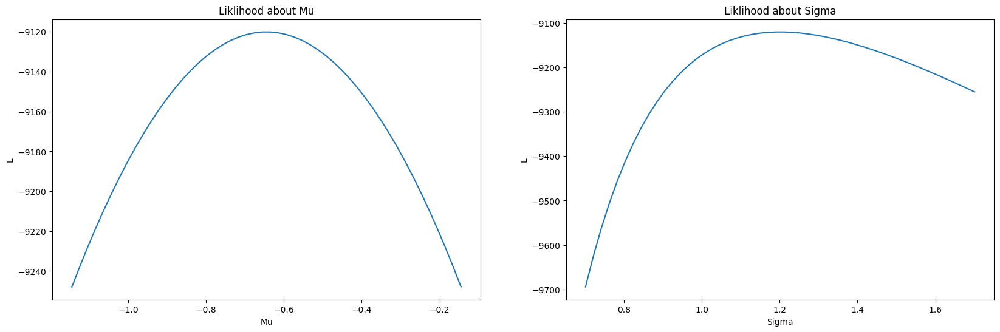

In [71]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
mu_test = np.linspace(mu_naive - 0.5, mu_naive + 0.5, 50)
L_mu = [lnlike_naive((mu, sigma_naive)) for mu in mu_test]

plt.plot(mu_test, L_mu)
plt.xlabel('Mu')
plt.ylabel('L')
plt.title('Liklihood about Mu')

plt.subplot(1, 2, 2)
sigma_test = np.linspace(sigma_naive - 0.5, sigma_naive + 0.5, 50)
L_mu = [lnlike_naive((mu_naive, sigma)) for sigma in sigma_test]

plt.plot(sigma_test, L_mu)
plt.xlabel('Sigma')
plt.ylabel('L')
plt.title('Liklihood about Sigma')

In [72]:
from numdifftools import Hessian

H = Hessian(lambda p: -lnlike_naive(p))(res_naive.x)
cov = np.linalg.inv(H)

naive_uncert = np.sqrt(np.diag(cov))
print(naive_uncert)

[0.03125794 0.02290857]


In [73]:
def fdet(mu, sigma):

    prior = norm.pdf(lnF_grid, loc = mu, scale = sigma)

    integrand = (pdet_gamma(F_grid) * prior)

    return np.trapezoid(integrand, lnF_grid)

def lnlike_detect(theta):

    mu, sigma = theta

    if sigma <= 0:
        return -np.inf

    probs = np.array([p_n_given_mu_sigma(ni, mu, sigma) for ni in n])

    return (np.sum(np.log(probs)) - len(n)*np.log(fdet(mu, sigma)))

In [74]:
res_detect = minimize(lambda p: -lnlike_detect(p), x0 = res_naive.x, method = 'Nelder-Mead')
print(res_detect.x)

[-2.14081583  2.0031187 ]


In [75]:
mu_det, sigma_det = res_detect.x

Text(0.5, 1.0, 'Liklihood about Sigma')

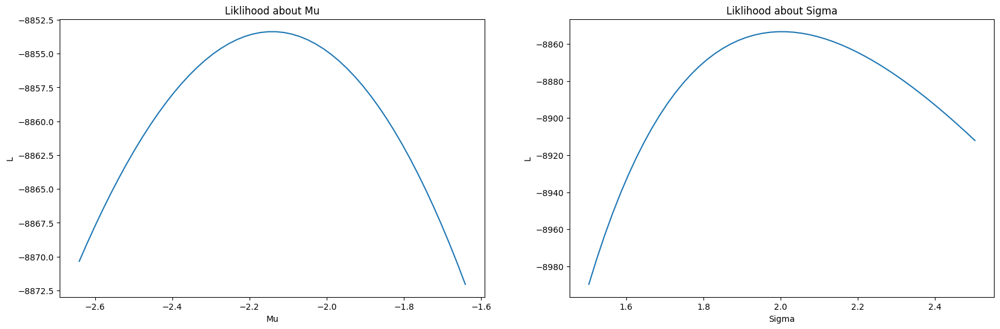

In [76]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
mu_test = np.linspace(mu_det - 0.5, mu_det + 0.5, 50)
L_mu = [lnlike_detect((mu, sigma_det)) for mu in mu_test]

plt.plot(mu_test, L_mu)
plt.xlabel('Mu')
plt.ylabel('L')
plt.title('Liklihood about Mu')

plt.subplot(1, 2, 2)
sigma_test = np.linspace(sigma_det - 0.5, sigma_det + 0.5, 50)
L_mu = [lnlike_detect((mu_det, sigma)) for sigma in sigma_test]

plt.plot(sigma_test, L_mu)
plt.xlabel('Sigma')
plt.ylabel('L')
plt.title('Liklihood about Sigma')

In [77]:
H = Hessian(lambda p: -lnlike_detect(p))(res_detect.x)
cov = np.linalg.inv(H)

detect_uncert = np.sqrt(np.diag(cov))

print(detect_uncert)

[0.23572636 0.10801876]


In [78]:
fd = fdet(mu_det, sigma_det)

print(f'The fraction detected is: {fd:.3f}')

The fraction detected is: 0.529


In [79]:
Ndet = 1500
Ntrue = Ndet / fd
Nmiss = Ntrue - Ndet

print(f'Ntrue = {Ntrue:.3f}')
print(f'Nmiss = {Nmiss:.3f}')

Ntrue = 2833.459
Nmiss = 1333.459


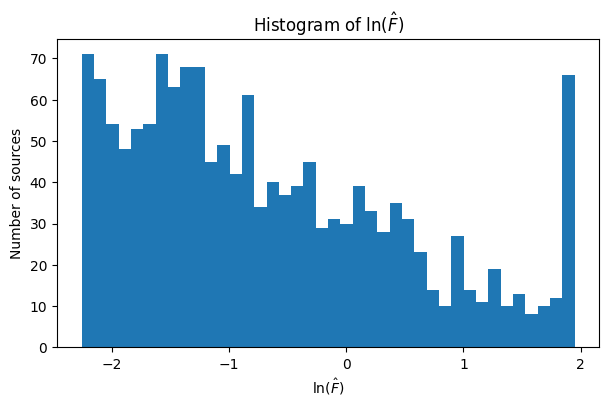

In [80]:
Fhat = (n - nu) / eps
lnFhat = np.log(Fhat)

plt.figure(figsize=(7,4))
plt.hist(lnFhat, bins = 40)

plt.xlabel(r'$\ln(\hat F)$')
plt.ylabel('Number of sources')

plt.title(r'Histogram of $\ln(\hat F)$')

plt.show()

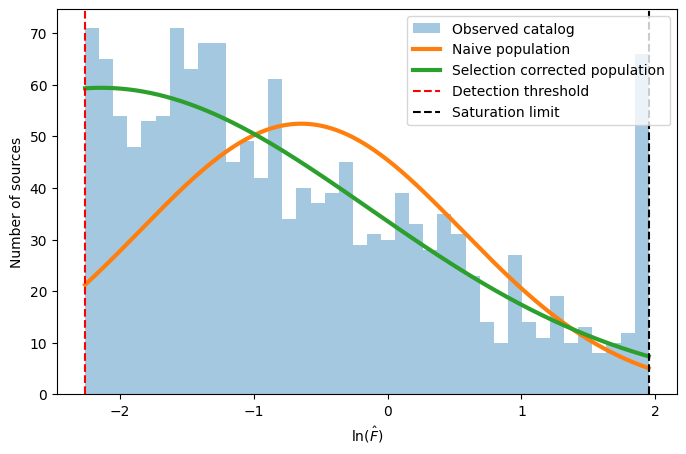

In [81]:
from scipy.stats import norm

plt.figure(figsize=(8,5))

counts, bins, _ = plt.hist(lnFhat, bins = 40, alpha = 0.4, label = 'Observed catalog')

bin_width = bins[1] - bins[0]

x = np.linspace(bins[0], bins[-1], 1000)

# naive population
y_naive = (len(n) * bin_width * norm.pdf(x, loc = mu_naive, scale = sigma_naive))

# corrected population
y_det = (Ntrue * bin_width * norm.pdf(x, loc = mu_det, scale = sigma_det))

plt.plot(x, y_naive, lw = 3, label = 'Naive population')
plt.plot(x, y_det, lw = 3, label = 'Selection corrected population')

plt.xlabel(r'$\ln(\hat F)$')
plt.ylabel('Number of sources')

plt.axvline(np.log((33 - nu)/eps), ls = '--', color = 'red', label = 'Detection threshold')
plt.axvline(np.log((1600 - nu)/eps), ls = '--', color = 'black', label = 'Saturation limit')

plt.legend()

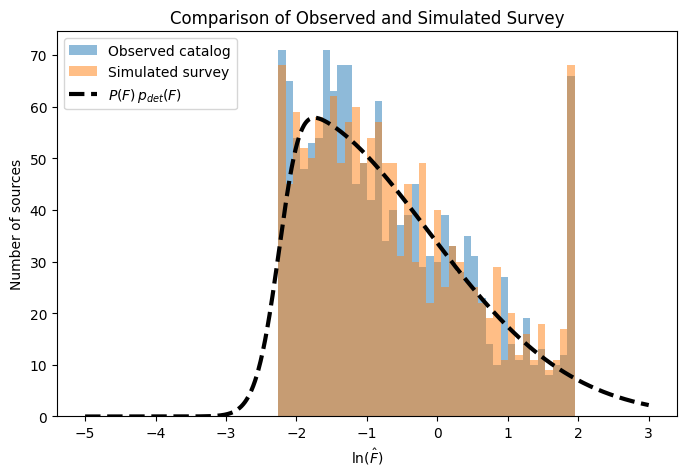

In [83]:
rng = np.random.default_rng(110426)

lnF_true = rng.normal(mu_det, sigma_det, int(round(Ntrue)))
F_true = np.exp(lnF_true)

lam = eps * F_true + nu
n_sim = rng.poisson(lam)

keep = n_sim > 32
n_sim = n_sim[keep]

n_sim = np.minimum(n_sim, 1600)

Fhat_sim = (n_sim - nu)/eps
lnFhat_sim = np.log(Fhat_sim)

plt.figure(figsize=(8,5))

plt.hist(lnFhat, bins = 40, alpha = 0.5, density = False, label = 'Observed catalog')
plt.hist(lnFhat_sim, bins = 40, alpha = 0.5, density = False, label = 'Simulated survey')

plt.title('Comparison of Observed and Simulated Survey')
plt.xlabel(r'$\ln(\hat F)$')
plt.ylabel('Number of sources')

x = np.linspace(-5, 3, 1000)

F = np.exp(x)

pop_detected = (Ntrue * pdet_gamma(F) * norm.pdf(x, loc = mu_det, scale = sigma_det))
pop_detected *= bin_width

y_detected = (Ntrue * bin_width * pdet_gamma(np.exp(x)) * norm.pdf(x, loc = mu_det, scale = sigma_det))

plt.plot(x, y_detected, lw = 3, color = 'black', linestyle = '--', label = r'$P(F)\,p_{det}(F)$')

plt.legend()

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

*Fit (naive): mu = -.645 +- .236, sigma = 1.201 +- .023

Fit (true): mu = -2.141 +- .236, sigma = 2.003 +- .108*

Number Missed: ~1334

Explanation: The fits don't compare do to Malquist Bias. Fainter stars don't get detected by the model and are left out of the data. This biases the sample as it misses a loarge population of the stars. If you didn't include all the faint stars that aren't in the data, then mu appears larger than it really is as its only catching the brightest objects. The fits don't completly match as some of the fainter objects are biased up (the scatter pushes some objects over the detection threshold due to the random noise). The scatter also is biased low as it isn't taking the full range of stellar magnitudes into consideration. 

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [48]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2009D: z = 0.025, B maximum at MJD 54840.88, 125 points; held-out band: V


In [49]:
d

,mjd,band,wavelength_A,flux_ujy,flux_err_ujy,mag,mag_err
0,54834.17,u,3639.3,757.9,7.68,16.759,0.011
1,54834.17,B,4350.6,1333.0,8.59,16.213,0.007
2,54834.17,g,4765.1,1343.0,6.18,16.097,0.005
3,54834.17,V,5375.2,1202.0,6.64,16.220,0.006
4,54834.17,r,6223.3,1151.0,6.36,16.253,0.006
...,...,...,...,...,...,...,...
120,54884.03,B,4350.6,100.8,2.88,19.016,0.031
121,54884.03,g,4765.1,141.0,1.17,18.544,0.009
122,54884.03,V,5375.2,245.5,3.62,17.945,0.016
123,54884.03,r,6223.3,350.3,1.94,17.545,0.006


In [50]:
# rest-frame phase
d['phase'] = (d['mjd'] - tmax) / (1 + z)

# assignment range
selected_d = d[(d['phase'] >= -10) & (d['phase'] <= 40)].copy()

# peak B flux
peak_B_flux = selected_d.loc[selected_d['band'] == 'B', 'flux_ujy'].max()

# normalized fluxes
selected_d['flux_norm'] = (selected_d['flux_ujy'] / peak_B_flux)
selected_d['flux_err_norm'] = (selected_d['flux_err_ujy'] / peak_B_flux)

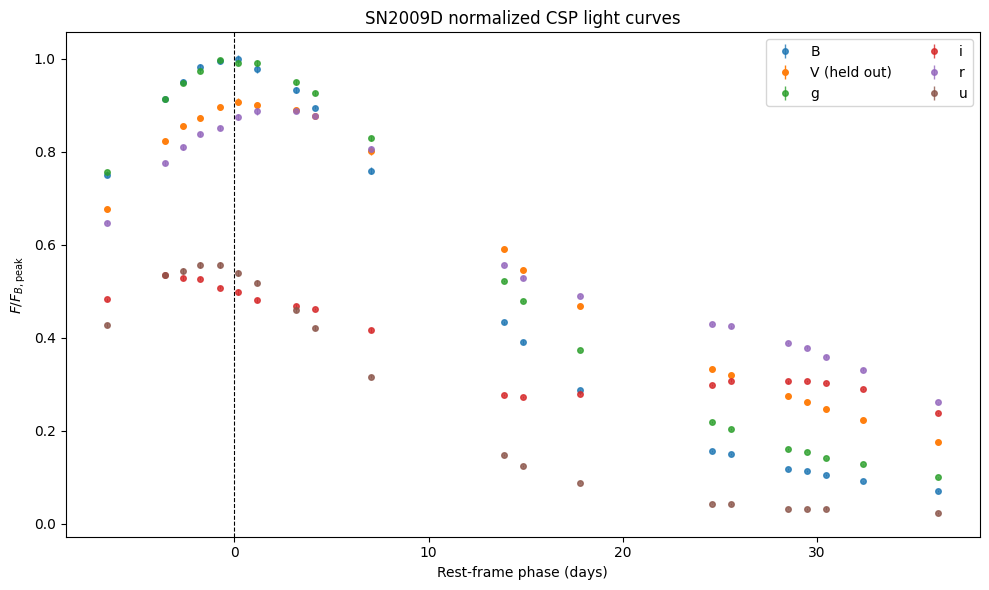

In [51]:
plt.figure(figsize=(10,6))

for band, g in selected_d.groupby('band'):

    if band == HOLD:
        plt.errorbar(g['phase'], g['flux_norm'], g['flux_err_norm'], fmt = 'o', ms=4, lw = 1, label = f'{band} (held out)'
        )
    else:
        plt.errorbar(g['phase'], g['flux_norm'], g['flux_err_norm'], fmt = 'o', ms = 4, lw = 1, alpha = 0.8, label = band)

plt.axvline(0, color = 'k', ls = '--', lw = 0.8)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel(r'$F/F_{B,\mathrm{peak}}$')

plt.title(f'{SN} normalized CSP light curves')

plt.legend(ncol = 2)

plt.tight_layout()

In [52]:
train = selected_d[selected_d['band'] != HOLD].copy()
test = selected_d[selected_d['band'] == HOLD].copy()

train['wave_um'] = train['wavelength_A'] / 1e4
test['wave_um'] = test['wavelength_A'] / 1e4

In [53]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (ConstantKernel, RBF, WhiteKernel)

X_train = train[['phase', 'wave_um']].to_numpy()
y_train = train['flux_norm'].to_numpy()
yerr_train = train['flux_err_norm'].to_numpy()

kernel = (ConstantKernel(constant_value = 1.0, constant_value_bounds = (1e-3, 10)) * RBF(length_scale=[10.0, 0.2], length_scale_bounds = ((0.1, 50), (0.01, 5))) + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1)))
gp = GaussianProcessRegressor(kernel=kernel, alpha = yerr_train**2, normalize_y = False, n_restarts_optimizer = 10)

gp.fit(X_train, y_train)
print(gp.kernel_)

0.306**2 * RBF(length_scale=[8.38, 0.117]) + WhiteKernel(noise_level=1.97e-06)


In [54]:
X_test = test[['phase', 'wave_um']].to_numpy()

pred_mean, pred_std = gp.predict(X_test, return_std = True)

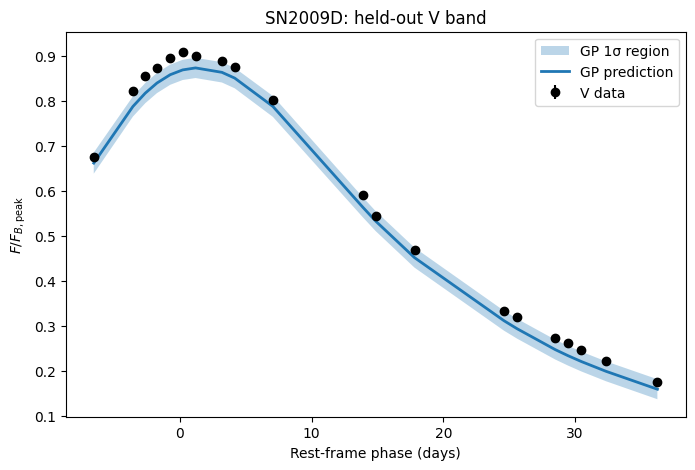

In [55]:
order = np.argsort(test['phase'].to_numpy())
phase_test = test['phase'].to_numpy()[order]
flux_test = test['flux_norm'].to_numpy()[order]
fluxerr_test = test['flux_err_norm'].to_numpy()[order]
pred_mean = pred_mean[order]
pred_std = pred_std[order]

plt.figure(figsize=(8,5))

plt.fill_between(phase_test, pred_mean - pred_std, pred_mean + pred_std, alpha = 0.3, label = 'GP 1σ region')
plt.plot(phase_test, pred_mean, lw = 2, label = 'GP prediction')
plt.errorbar(phase_test, flux_test, fluxerr_test, fmt = 'o', color = 'k', label = f'{HOLD} data')

plt.xlabel('Rest-frame phase (days)')
plt.ylabel(r'$F/F_{B,\rm peak}$')

plt.title(f'{SN}: held-out {HOLD} band')

plt.legend()

In [56]:
resid = flux_test - pred_mean
rms = np.sqrt(np.mean(resid**2))

print(f'RMS residual = {rms:.4f}')

RMS residual = 0.0266


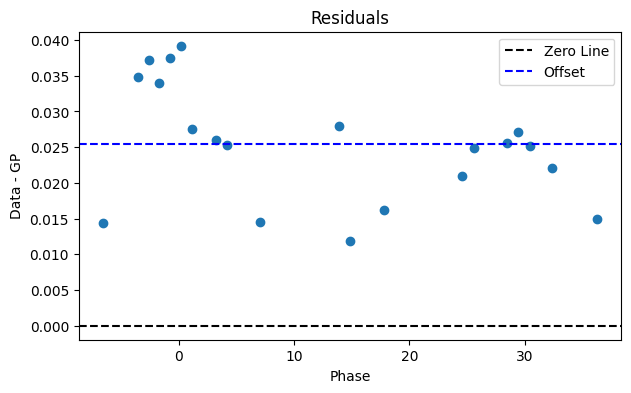

In [57]:
plt.figure(figsize=(7,4))

plt.axhline(0, color='k', linestyle ='--', label = 'Zero Line')
plt.axhline(0.0255, color = 'blue',linestyle = '--', label = 'Offset')

plt.scatter(phase_test, resid)

plt.xlabel("Phase")
plt.ylabel("Data - GP")
plt.title("Residuals")
plt.legend()

The errorbars actually look reasonable for the fit as they all follow the shape and curve of the fit. However, the fit itself is biased low (as all the points have a positive residual). If the model was correctly centered the points would all fit within the bounds of coverage.

In [58]:
sigma_total = np.sqrt(pred_std**2 + fluxerr_test**2)

inside = np.abs(resid) <= sigma_total
frac_inside = inside.mean()

print(f'Fraction within 1σ = {frac_inside:.3f}')

Fraction within 1σ = 0.300


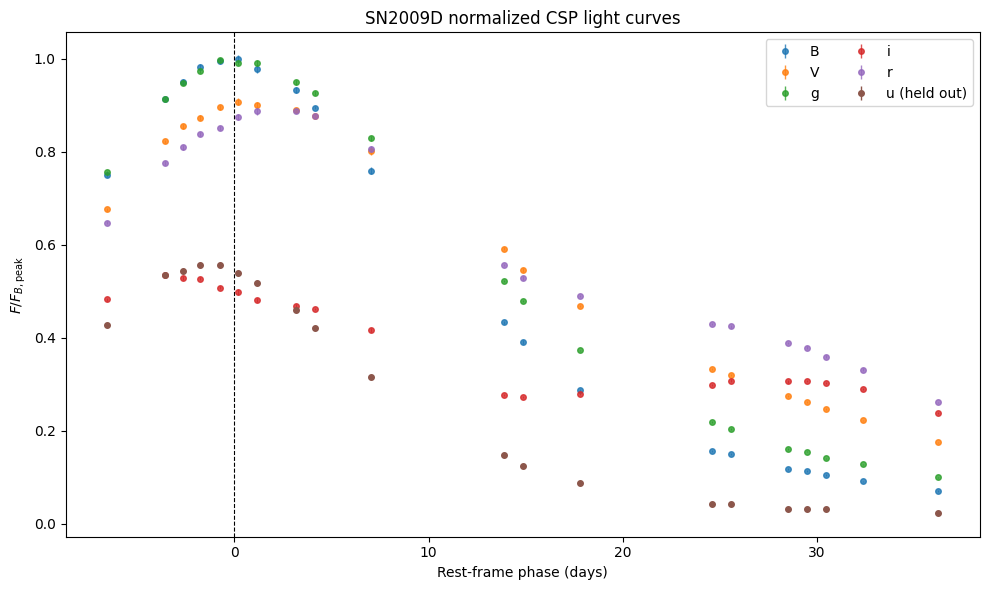

In [59]:
plt.figure(figsize=(10,6))

for band, g in selected_d.groupby('band'):

    if band == 'u':
        plt.errorbar(g['phase'], g['flux_norm'], g['flux_err_norm'], fmt = 'o', ms=4, lw = 1, label = f'{band} (held out)'
        )
    else:
        plt.errorbar(g['phase'], g['flux_norm'], g['flux_err_norm'], fmt = 'o', ms = 4, lw = 1, alpha = 0.8, label = band)

plt.axvline(0, color = 'k', ls = '--', lw = 0.8)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel(r'$F/F_{B,\mathrm{peak}}$')

plt.title(f'{SN} normalized CSP light curves')

plt.legend(ncol = 2)

plt.tight_layout()

In [60]:
train = selected_d[selected_d['band'] != 'u'].copy()
test = selected_d[selected_d['band'] == 'u'].copy()

train['wave_um'] = train['wavelength_A'] / 1e4
test['wave_um'] = test['wavelength_A'] / 1e4

In [61]:
X_train = train[['phase', 'wave_um']].to_numpy()
y_train = train['flux_norm'].to_numpy()
yerr_train = train['flux_err_norm'].to_numpy()

kernel = (ConstantKernel(constant_value = 1.0, constant_value_bounds = (1e-3, 10)) * RBF(length_scale=[10.0, 0.2], length_scale_bounds = ((0.1, 50), (0.01, 5))) + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1)))
gp = GaussianProcessRegressor(kernel=kernel, alpha = yerr_train**2, normalize_y = False, n_restarts_optimizer = 10)

gp.fit(X_train, y_train)
print(gp.kernel_)

0.292**2 * RBF(length_scale=[8.07, 0.133]) + WhiteKernel(noise_level=1.64e-06)


In [62]:
X_test = test[['phase', 'wave_um']].to_numpy()

pred_mean, pred_std = gp.predict(X_test, return_std = True)

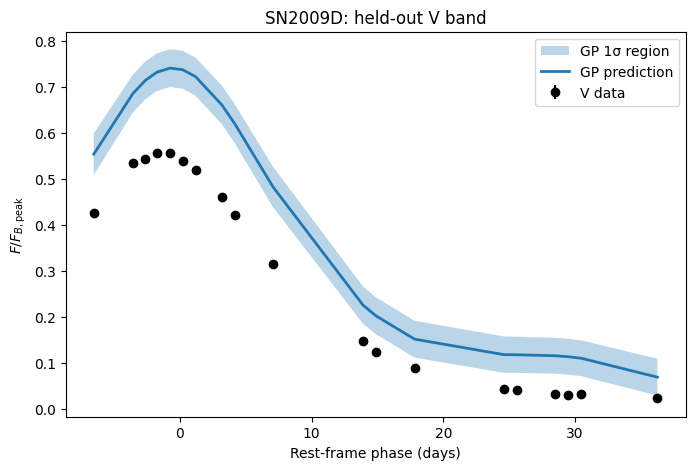

In [63]:
order = np.argsort(test['phase'].to_numpy())
phase_test = test['phase'].to_numpy()[order]
flux_test = test['flux_norm'].to_numpy()[order]
fluxerr_test = test['flux_err_norm'].to_numpy()[order]
pred_mean = pred_mean[order]
pred_std = pred_std[order]

plt.figure(figsize=(8,5))

plt.fill_between(phase_test, pred_mean - pred_std, pred_mean + pred_std, alpha = 0.3, label = 'GP 1σ region')
plt.plot(phase_test, pred_mean, lw = 2, label = 'GP prediction')
plt.errorbar(phase_test, flux_test, fluxerr_test, fmt = 'o', color = 'k', label = f'{HOLD} data')

plt.xlabel('Rest-frame phase (days)')
plt.ylabel(r'$F/F_{B,\rm peak}$')

plt.title(f'{SN}: held-out {HOLD} band')

plt.legend()

In [64]:
resid = flux_test - pred_mean
rms = np.sqrt(np.mean(resid**2))

print(f'RMS residual = {rms:.4f}')

RMS residual = 0.1395


In [65]:
sigma_total = np.sqrt(pred_std**2 + fluxerr_test**2)

inside = np.abs(resid) <= sigma_total
frac_inside = inside.mean()

print(f'Fraction within 1σ = {frac_inside:.3f}')

Fraction within 1σ = 0.000


**ANSWER (length scales, the two held-out tests, then why u is harder):**

*Length Scale V: (8.38 to 0.117)
Length Scale u: (8.07, 0.133)*

Held-out V: .300
Held-out u: 0.00

Explanation: 
u is much harder as it doesn't sit between as many of the filters used to train the model. As it doesn't appear between as many of them, the range defined by teh other filters doesn't include as many of the points of the u filter. This causes an alternate projected fit for u that lies off the points. 

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

*I used Ai as a debugger and to help learn the content and ideate potential choices for handling analysis.*

**REFLECTION:**

*Initially, I thought about using my prior contaminent method again. I even put my previous method into the Ai for it to look over and determine how to create a PyMC off of it. However, after looking over the fit I decided to reject this. The Ai however, still remebered I did this and tried to advice me against this option. To fix this, I ignored the Ai's recommendations and restarted the project with a new Ai bot that didn't have old analysis in it.*

**VERIFICATION PLAN:**

*Some additional analysis I ran included making plots of the liklihood surrounding my fitted mus and sigmas. I wasn't sure whether or not the assumptions of the Hessian could be included in my analysis so I plotted out the curvature. A failure for this check would have been if the curvature visually wasn't Gaussian. If it wasn't gaussian, then I wouldn't have been able to trust the Hessian values.*

Text(0.5, 1.0, 'Liklihood about Sigma')

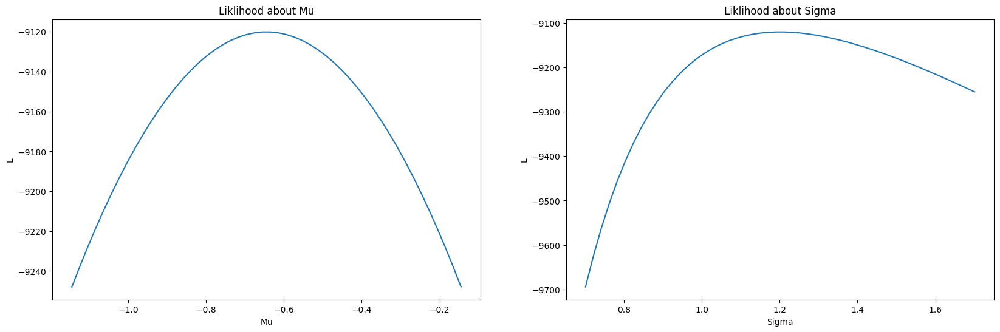

In [90]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
mu_test = np.linspace(mu_naive - 0.5, mu_naive + 0.5, 50)
L_mu = [lnlike_naive((mu, sigma_naive)) for mu in mu_test]

plt.plot(mu_test, L_mu)
plt.xlabel('Mu')
plt.ylabel('L')
plt.title('Liklihood about Mu')

plt.subplot(1, 2, 2)
sigma_test = np.linspace(sigma_naive - 0.5, sigma_naive + 0.5, 50)
L_mu = [lnlike_naive((mu_naive, sigma)) for sigma in sigma_test]

plt.plot(sigma_test, L_mu)
plt.xlabel('Sigma')
plt.ylabel('L')
plt.title('Liklihood about Sigma')

After looking at the liklihoods, they return curves that could be approximated as Gaussian allowing for the Hessian assumptions to hold. 